In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [2]:
class CricketState(TypedDict):
    t_runs : int
    balls : int
    fours : int
    sixes : int
    sr: float
    bp: float
    bpb: float
    summary: str

In [3]:
def StrikeRate(state: CricketState):

    sr = (state['t_runs']/state['balls'])*100

    return {'sr' :  sr}


In [4]:
def BoundaryPerc(state: CricketState):

    total_boundary_runs = (state['fours'])*4 + (state['sixes'])*6
    
    bp = (total_boundary_runs/state['t_runs'])*100

    return {'bp' :  bp}

In [5]:
def BallsperBoundary(state: CricketState):
    
    bpb = state['balls']/(state['fours'] + state['sixes'])

    return {'bpb' :  bpb}

In [6]:
def summary(state: CricketState):

    summary = f"""
    Strike-Rate: {state['sr']} \n
    Boundary-Percetage: {state['bp']} \n
    Balls-per-Boundary: {state['bpb']} \n
    """
    return {'summary' : summary}


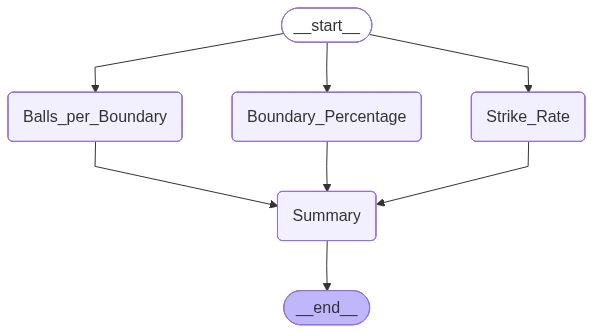

In [7]:
graph = StateGraph(CricketState)

graph.add_node('Boundary_Percentage', BoundaryPerc)

graph.add_node('Strike_Rate', StrikeRate)

graph.add_node('Balls_per_Boundary', BallsperBoundary)

graph.add_node('Summary', summary)

graph.add_edge(START, 'Strike_Rate')

graph.add_edge(START, 'Boundary_Percentage')

graph.add_edge(START, 'Balls_per_Boundary')

graph.add_edge(['Strike_Rate', 'Boundary_Percentage', 'Balls_per_Boundary'], 'Summary')

graph.add_edge('Summary', END)

parallel_workflow = graph.compile()

parallel_workflow

In [8]:
input_state = {'t_runs':100 , 'balls':50 , 'fours':6 , 'sixes':4 }

final_state = parallel_workflow.invoke(input_state)

print(final_state)

{'t_runs': 100, 'balls': 50, 'fours': 6, 'sixes': 4, 'sr': 200.0, 'bp': 48.0, 'bpb': 5.0, 'summary': '\n    Strike-Rate: 200.0 \n\n    Boundary-Percetage: 48.0 \n\n    Balls-per-Boundary: 5.0 \n\n    '}
